# Baselines: TF-IDF and logistic regression

This notebook covers the required baseline of the project: **TF-IDF features with logistic regression**, one model
for each target (recommendation and rating band). It answers four questions:

1. Which features and settings were chosen, and how?
2. Which changes to the baseline helped, and which did not?
3. How well does the chosen model do, on validation and on the test set?
4. What has it learned?

Nothing is trained here. Every number is read from the result files in `reports/`, written by the scripts named in
each section. The test set was read once, by `scripts/final_evaluation.py` (`reports/final_evaluation.json`); this
notebook only shows that result.

Only the review text (`body`, normalized as described in notebook 01) is used as input. The vocabulary and the IDF
weights are fitted on the training reviews only and applied unchanged to validation and test.

In [1]:
import glob
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

from digikala_reviews import plotting
from digikala_reviews.config import FIGURES_DIR, REPORTS_DIR
from digikala_reviews.tfidf import HEADS

plotting.apply_style()
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.4f}")
HEAD_TITLES = {"recommendation": "Recommendation", "rating_band": "Rating band"}


def load_report(name):
    return json.loads((REPORTS_DIR / name).read_text(encoding="utf-8"))


chosen = load_report("tfidf_final/chosen_model.json")
required = load_report("required_metrics.json")["heads"]
final = load_report("final_evaluation.json")["heads"]
words = load_report("tfidf_analysis/words.json")

## 1. Features

One vectorizer serves both heads (`src/digikala_reviews/tfidf.py`, setup `word123_min5_persian`):

- word 1, 2 and 3-grams, kept if they appear in at least 5 training reviews;
- a Persian token pattern: words of any length are kept whole across the half-space (`می‌خواهم` stays one token),
  and every emoji or punctuation mark is a token of its own, since `!` and emojis carry sentiment;
- sublinear term frequency (`1 + log(tf)`);
- no stop-word list: negation words such as `نه` and `نیست` are frequent and carry the label (section 6 of
  notebook 01; experiment E3 below shows what removing frequent words costs).

In [2]:
settings = pd.DataFrame(
    {
        head: {
            "regularization C": v["settings"]["C"],
            "class weights": v["settings"]["class_weight"] or "none",
            "training reviews": v["training_rows"],
            "converged": v["converged"],
            "fit time (minutes)": v["minutes"],
        }
        for head, v in chosen["heads"].items()
    }
)
print(f"Features: {chosen['features']:,} n-grams, fitted on the training reviews only")
settings

Features: 1,192,046 n-grams, fitted on the training reviews only


,recommendation,rating_band
regularization C,0.5000,1
class weights,balanced,none
training reviews,2944539,3270531
converged,True,True
fit time (minutes),9.2000,11.2000


## 2. Choosing the settings

`scripts/tune_tfidf.py` compared, on validation, four feature setups (stage 1) and then five values of the
regularization strength C for the best setup (stage 2), with and without balanced class weights. Every run
converged.

In [3]:
runs = []
for path in sorted(glob.glob(str(REPORTS_DIR / "tfidf_runs" / "*.json"))):
    r = json.loads(open(path, encoding="utf-8").read())
    runs.append(
        {
            "head": r["head"],
            "stage": r["stage"],
            "features": r["setup"],
            "class weights": r["class_weight"],
            "C": r["C"],
            "validation Macro F1": r["validation"]["macro_f1"],
            "fit minutes": round(r["fit_seconds"] / 60, 1),
        }
    )
runs = pd.DataFrame(runs).sort_values(["head", "validation Macro F1"], ascending=[True, False])
runs.groupby("head").head(6).reset_index(drop=True)

,head,stage,features,class weights,C,validation Macro F1,fit minutes
0,rating_band,features,word123_min5_persian,NaN,1,0.6459,39.4000
1,rating_band,regularization,word123_min5_persian,NaN,2,0.6450,35.9000
2,rating_band,features,word123_min5_persian,balanced,1,0.6443,51.1000
3,rating_band,features,word12_min2,NaN,1,0.6436,34.1000
4,rating_band,features,word12_min5,NaN,1,0.6431,18.6000
5,rating_band,features,word12_min5_persian,NaN,1,0.6431,21.5000
6,recommendation,regularization,word123_min5_persian,balanced,0.5000,0.6802,29.7000
7,recommendation,features,word123_min5_persian,balanced,1,0.6789,40.7000
8,recommendation,regularization,word123_min5_persian,balanced,0.2500,0.6784,18.9000
9,recommendation,features,word123_min5_persian,NaN,1,0.6783,24.4000


The differences between setups are small (under 1 point between the best and the worst). The word 1 to 3-grams with
the Persian token pattern were best for both heads. Recommendation is best with balanced class weights and C = 0.5,
the rating band without weights and C = 1. These two models are the **reference** for the experiments below.

## 3. Experiments on the baseline

Each experiment changes one thing in the reference and is scored on the same validation reviews. The plan, with its
expected outcomes, was written before the results (`reports/tfidf_experiment_plan.md`). A change is adopted only if
the whole 95% interval of the difference (paired bootstrap) is above zero.

In [4]:
experiments = []
for folder in ("tfidf_experiments", "tfidf_extra"):
    for path in sorted(glob.glob(str(REPORTS_DIR / folder / "E*.json"))):
        r = json.loads(open(path, encoding="utf-8").read())
        if r.get("macro_f1_difference") is None:
            continue  # E9, E10 and E12 are shown further down
        experiments.append(
            {
                "experiment": r["experiment"],
                "head": r["head"],
                "change": r["variant"].replace("_", " "),
                "difference (points)": 100 * r["macro_f1_difference"],
                "95% interval": "[{:+.2f}, {:+.2f}]".format(*[100 * v for v in r["difference_interval_95"]]),
                "verdict": r["verdict"],
            }
        )
experiments = pd.DataFrame(experiments)
experiments["order"] = experiments["experiment"].str[1:].astype(int)
experiments.sort_values(["order", "head"]).drop(columns="order").reset_index(drop=True)

,experiment,head,change,difference (points),95% interval,verdict
0,E1,rating_band,offsets,2.1745,"[+2.09, +2.26]",better
1,E1,recommendation,offsets,2.1737,"[+2.07, +2.27]",better
2,E2,rating_band,word plus char,0.1695,"[+0.11, +0.24]",better
3,E2,recommendation,word plus char,-0.0310,"[-0.09, +0.03]",no measurable difference
4,E3,rating_band,frequent words removed,-7.9757,"[-8.12, -7.85]",worse
5,E3,recommendation,frequent words removed,-7.1424,"[-7.27, -7.01]",worse
6,E4,rating_band,ordinal,-0.1668,"[-0.24, -0.09]",worse
7,E5,rating_band,plain tf,-0.0300,"[-0.08, +0.02]",no measurable difference
8,E5,recommendation,plain tf,-0.0078,"[-0.04, +0.02]",no measurable difference
9,E6,rating_band,complement nb alpha0.1,-2.0902,"[-2.22, -1.96]",report only


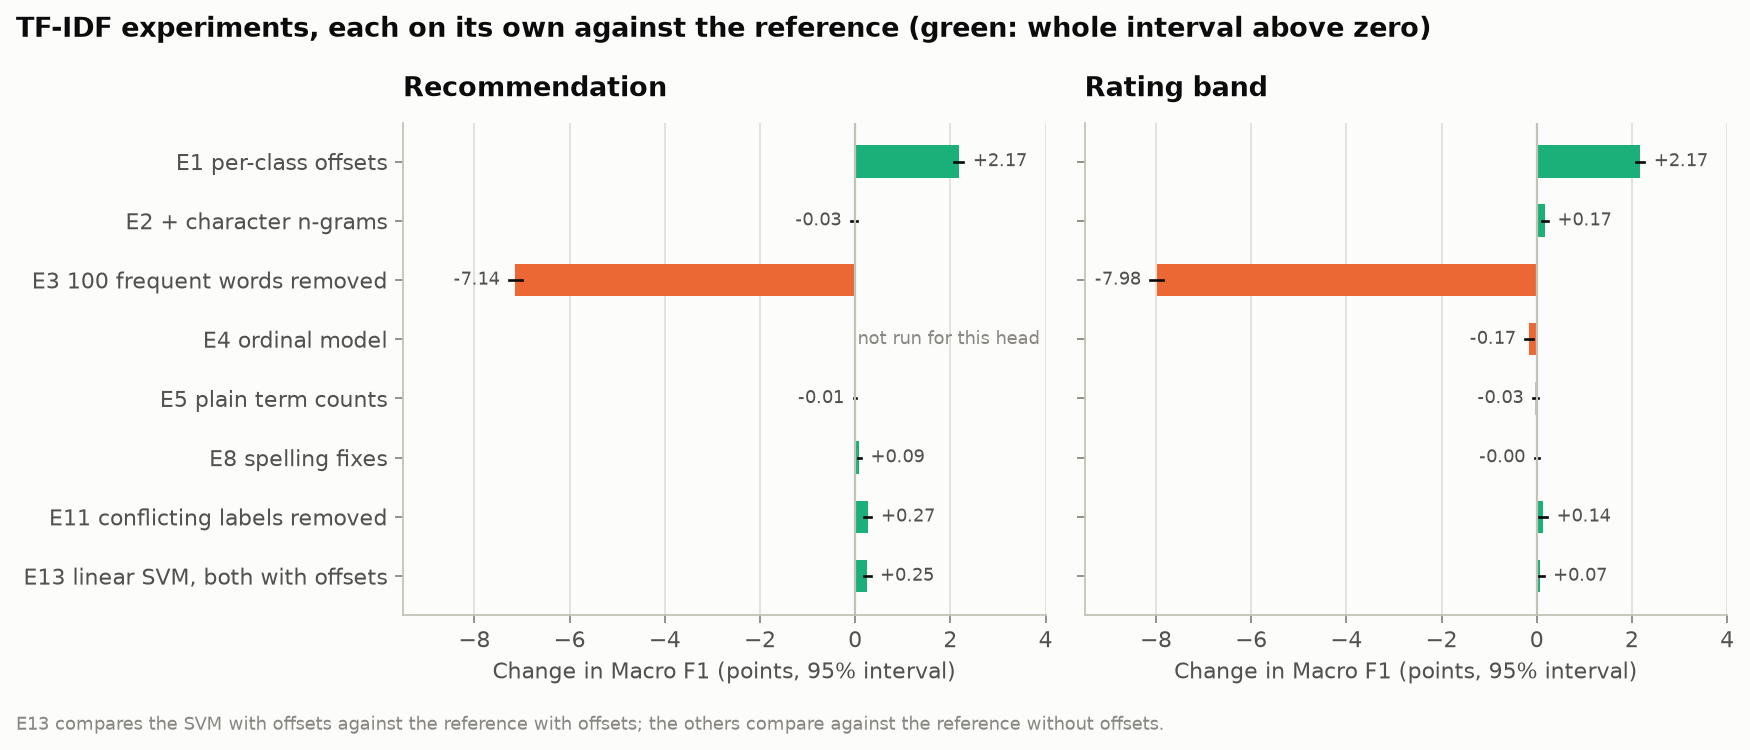

In [5]:
Image(FIGURES_DIR / "results_tfidf_experiments.png")

What the experiments show:

- **E1, per-class offsets**, is by far the largest gain: +2.2 points on both heads. Logistic regression is trained
  for overall likelihood and under-predicts the small classes; an offset per class, tuned on one half of validation
  and scored on the other, moves the decisions towards them.
- **E3, removing the 100 most frequent words**, costs 7 to 8 points: frequent words such as `ولی` ("but") and the
  negations carry the label.
- E2 (character n-grams), E8 (spelling fixes) and E11 (conflicting labels removed) gave small gains on one or both
  heads alone, but next
  to the offsets they added nothing on recommendation and made the rating band worse (section "The final model" of
  the plan). **The model kept is the reference with offsets**, for both heads: the simpler model, chosen on
  validation before the test set was read.
- E6: a linear SVM (C = 0.1) would be close; with offsets it is +0.25 point on recommendation (E13). The project
  asks for logistic regression, so it stays.
- E4: an ordinal model for the rating band was worse (-0.17 point).

### How the split and the amount of data matter (report only)

- **E9**: a random split instead of a split by product changes Macro F1 by less than 0.2 point here, so the
  baseline does not profit from remembering products.
- **E10**: training on older reviews and scoring the newest year.
- **E12**: the same model trained on 10,000, 100,000 and 1,000,000 reviews.

In [6]:
extra = []
for path in sorted(glob.glob(str(REPORTS_DIR / "tfidf_extra" / "E*.json"))):
    r = json.loads(open(path, encoding="utf-8").read())
    if r["experiment"] in ("E9", "E10", "E12"):
        extra.append(
            {
                "experiment": r["experiment"],
                "head": r["head"],
                "variant": r["variant"],
                "training reviews": r.get("training_reviews") or r.get("train_reviews"),
                "validation Macro F1": r["scores"]["macro_f1"],
            }
        )
pd.DataFrame(extra)

,experiment,head,variant,training reviews,validation Macro F1
0,E10,rating_band,by_time,2753299,0.6708
1,E10,recommendation,by_time,2529932,0.6780
2,E12,rating_band,n10000,10000,0.5496
3,E12,rating_band,n100000,100000,0.6074
4,E12,rating_band,n1000000,1000000,0.6355
5,E12,recommendation,n10000,10000,0.6150
6,E12,recommendation,n100000,100000,0.6487
7,E12,recommendation,n1000000,1000000,0.6720
8,E9,rating_band,by_product,2859998,0.6448
9,E9,rating_band,random,2859331,0.6464


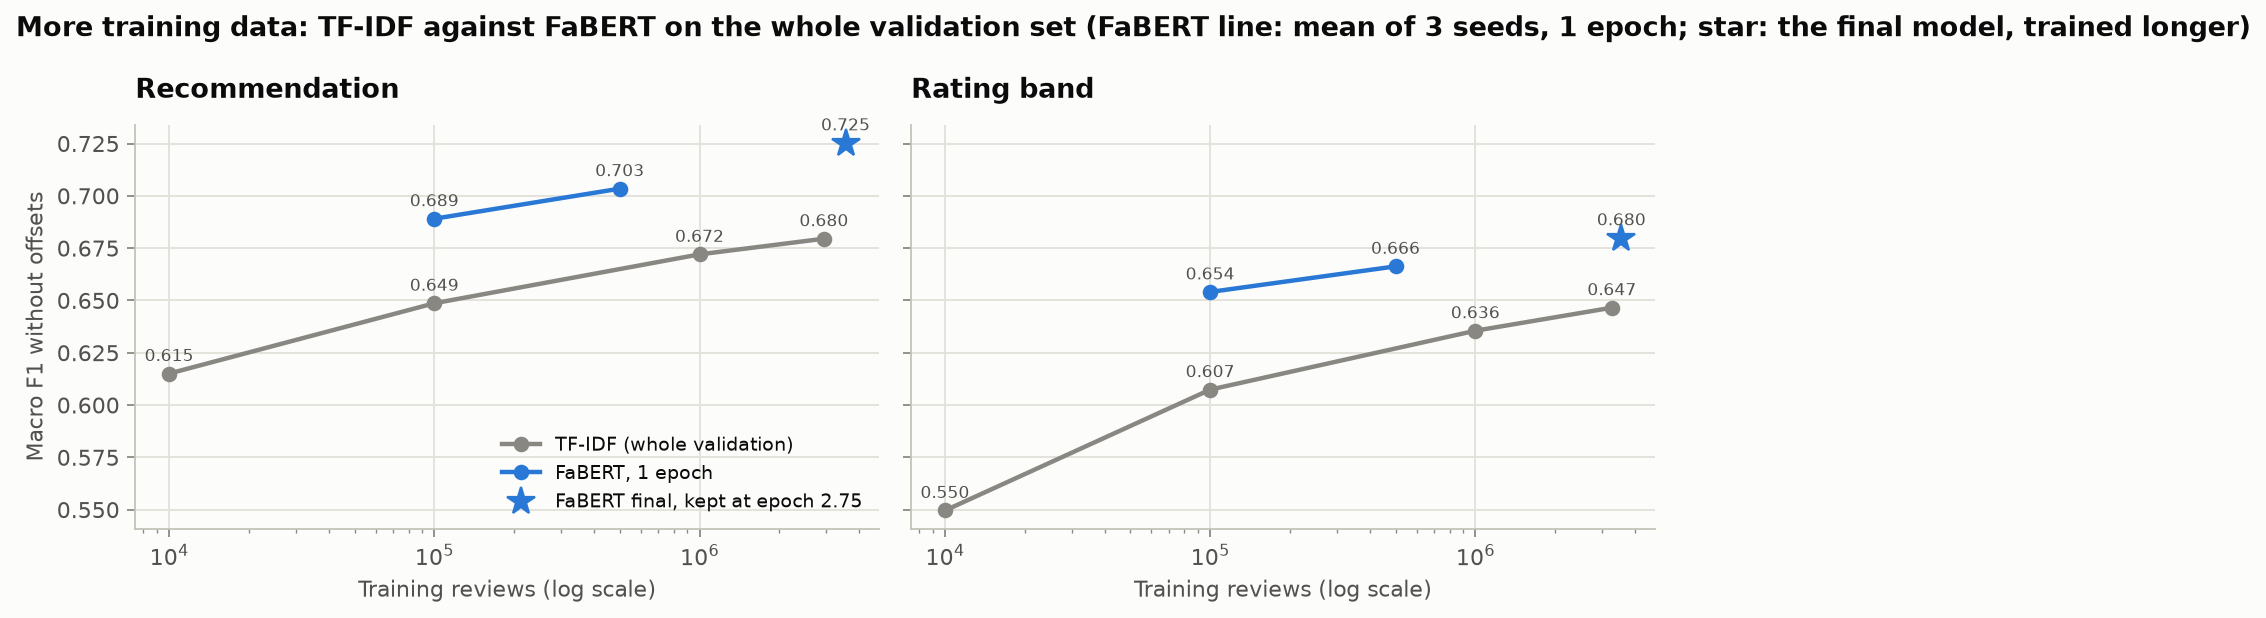

In [7]:
Image(FIGURES_DIR / "results_learning_curve.png")

The baseline gains 6 to 9 points from 10,000 to 1,000,000 reviews and only about 1 more point from 1,000,000 to
all of them: it is close to what this kind of model can learn from the text.

## 4. Offsets

The offsets are added to the log-probabilities before the class is chosen. For the test set they were tuned once on
all of validation (`offsets_for_test`). On validation every review is scored with offsets tuned on the other half
(split by product), so no review is judged with offsets fitted on it.

In [8]:
offsets = pd.DataFrame({head: v["offsets_for_test"] for head, v in chosen["heads"].items()}).T
recall = []
for head, v in chosen["heads"].items():
    for label in HEADS[head]["labels"]:
        recall.append(
            {
                "head": head,
                "class": label,
                "recall without offsets": v["validation_without_offsets"]["per_class"][label]["recall"],
                "recall with offsets": v["validation_with_offsets"]["per_class"][label]["recall"],
            }
        )
display(offsets.fillna(""))
pd.DataFrame(recall)

/tmp/ipykernel_651/2928648966.py:13: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(offsets.fillna(""))


,no_idea,not_recommended,recommended,high,low,medium
recommendation,0,-0.4000,0.7000,,,
rating_band,,,,0,0.7000,0.8000


,head,class,recall without offsets,recall with offsets
0,recommendation,recommended,0.8458,0.9134
1,recommendation,not_recommended,0.7761,0.6845
2,recommendation,no_idea,0.5845,0.5351
3,rating_band,low,0.6514,0.6465
4,rating_band,medium,0.2753,0.4514
5,rating_band,high,0.9545,0.8807


The offsets trade recall of the large classes (`recommended`, `high`) for the small ones. The largest change is the
`medium` band, whose recall rises from 0.28 to 0.45.

## 5. Results

All required scores of the chosen model, with offsets, on the whole validation set (`reports/required_metrics.json`)
and on the test set (`reports/final_evaluation.json`). Balanced accuracy is the mean recall of the classes. The
ordinal distance error is the mean number of bands a prediction is off (low against high counts as 2).

In [9]:
rows = []
for head in HEADS:
    for part, scores in [
        ("validation", required[head]["tfidf"]),
        ("test", final[head]["models"]["tfidf"]["with_offsets"]),
    ]:
        row = {
            "head": head,
            "set": part,
            "reviews": scores["rows"],
            "accuracy": scores["accuracy"],
            "Macro F1": scores["macro_f1"],
            "Macro precision": scores["macro_precision"],
            "Macro recall": scores["macro_recall"],
            "balanced accuracy": scores["balanced_accuracy"],
        }
        if head == "rating_band":
            row["ordinal distance"] = scores["ordinal_distance_error"]["mean_distance"]
            row["off by two"] = scores["ordinal_distance_error"]["share_off_by_two"]
        rows.append(row)
pd.DataFrame(rows).fillna("")

/tmp/ipykernel_651/2001920786.py:21: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame(rows).fillna("")


,head,set,reviews,accuracy,Macro F1,Macro precision,Macro recall,balanced accuracy,ordinal distance,off by two
0,recommendation,validation,788717,0.8487,0.7017,0.6976,0.7110,0.7110,,
1,recommendation,test,788717,0.8490,0.7021,0.6985,0.7111,0.7111,,
2,rating_band,validation,843458,0.7765,0.6683,0.6781,0.6596,0.6596,0.2405,0.0170
3,rating_band,test,843458,0.7765,0.6684,0.6757,0.6617,0.6617,0.2409,0.0174


In [10]:
low, high = final["recommendation"]["models"]["tfidf"]["macro_f1_interval_95_products"]
print(f"Test Macro F1, recommendation: 95% interval [{low:.4f}, {high:.4f}] (products drawn)")
low, high = final["rating_band"]["models"]["tfidf"]["macro_f1_interval_95_products"]
print(f"Test Macro F1, rating band:    95% interval [{low:.4f}, {high:.4f}] (products drawn)")

Test Macro F1, recommendation: 95% interval [0.7005, 0.7036] (products drawn)
Test Macro F1, rating band:    95% interval [0.6668, 0.6700] (products drawn)


In [11]:
per_class = []
for head in HEADS:
    for part, scores in [
        ("validation", required[head]["tfidf"]),
        ("test", final[head]["models"]["tfidf"]["with_offsets"]),
    ]:
        for label, c in scores["per_class"].items():
            per_class.append(
                {
                    "head": head,
                    "class": label,
                    "set": part,
                    "precision": c["precision"],
                    "recall": c["recall"],
                    "F1": c["f1"],
                }
            )
pd.DataFrame(per_class).pivot_table(
    index=["head", "class"], columns="set", values=["precision", "recall", "F1"], sort=False
)

precision            recall                F1  \
set                            validation   test validation   test validation   
head           class                                                            
recommendation recommended         0.9432 0.9431     0.9134 0.9137     0.9280   
               not_recommended     0.7297 0.7313     0.6845 0.6825     0.7064   
               no_idea             0.4200 0.4212     0.5351 0.5371     0.4706   
rating_band    low                 0.7139 0.7058     0.6465 0.6583     0.6785   
               medium              0.4514 0.4520     0.4514 0.4462     0.4514   
               high                0.8692 0.8693     0.8807 0.8805     0.8749   

                                       
set                              test  
head           class                   
recommendation recommended     0.9281  
               not_recommended 0.7061  
               no_idea         0.4721  
rating_band    low             0.6812  
               medium          0.4490  
               high            0.8749

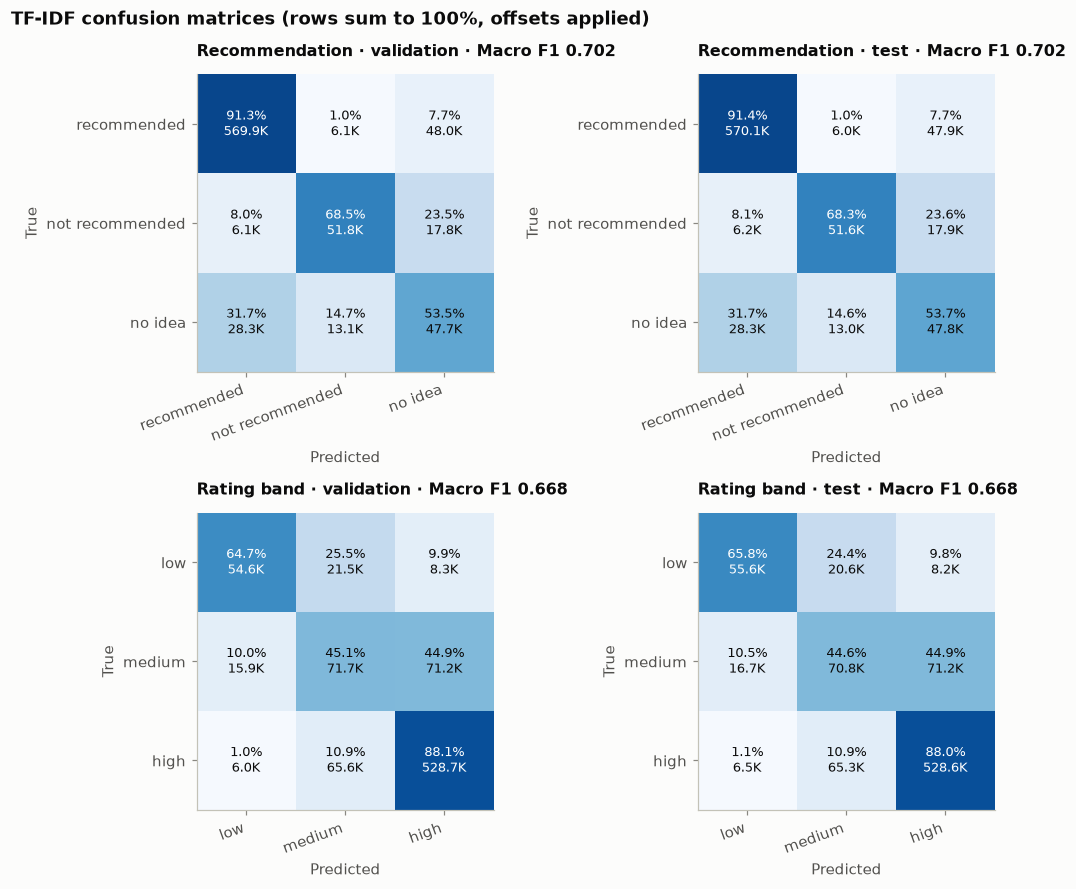

In [12]:
def draw_confusion(ax, scores, title):
    labels = scores["confusion_matrix"]["labels"]
    counts = np.array(scores["confusion_matrix"]["rows_are_true_class"], dtype=float)
    shares = counts / counts.sum(axis=1, keepdims=True) * 100
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=100)
    ax.grid(False)
    for i in range(len(labels)):
        for j in range(len(labels)):
            color = "white" if shares[i, j] > 55 else plotting.INK
            ax.text(
                j,
                i,
                f"{shares[i, j]:.1f}%\n{plotting.compact(counts[i, j])}",
                ha="center",
                va="center",
                fontsize=8.5,
                color=color,
            )
    names = [label.replace("_", " ") for label in labels]
    ax.set_xticks(range(len(labels)), names, rotation=20, ha="right")
    ax.set_yticks(range(len(labels)), names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title, fontsize=10.5)


fig, axes = plt.subplots(2, 2, figsize=(9.5, 8.2))
for row, head in enumerate(HEADS):
    for col, (part, scores) in enumerate(
        [("validation", required[head]["tfidf"]), ("test", final[head]["models"]["tfidf"]["with_offsets"])]
    ):
        draw_confusion(
            axes[row][col], scores, f"{HEAD_TITLES[head]} · {part} · Macro F1 {scores['macro_f1']:.3f}"
        )
fig.suptitle(
    "TF-IDF confusion matrices (rows sum to 100%, offsets applied)",
    x=0.01,
    ha="left",
    fontsize=12,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

Validation and test agree to within 0.05 point of Macro F1 on both heads: the many choices made on validation did
not fit the model to it. The hard classes are `no_idea` and `medium`. Missed `no_idea` reviews go mostly to
`recommended` (about two thirds of them), and missed `medium` reviews mostly to `high` (more than four fifths). Low
against high is rare: under 2% of the rating band reviews.

## 6. What the model learned

The n-grams with the largest weight for each class, minus their mean weight over the classes
(`reports/tfidf_analysis/words.json`, `scripts/analyze_tfidf.py`). The top 12 of each class.

In [13]:
for head in HEADS:
    table = pd.DataFrame(
        {label: [term for term, _ in words[head][label][:12]] for label in HEADS[head]["labels"]}
    )
    print(HEAD_TITLES[head])
    display(table)

Recommendation


,recommended,not_recommended,no_idea
0,بهترین,اصلا,نمیدونم
1,بد نیست,افتضاحه,اما
2,بد نبود,بدترین,ولی
3,خوبیه,افتضاح,شک دارم
4,عالی ،,متاسفم,نیستم
5,عالین,راضی نیستم,امیدوارم
6,اذیت نمیکنه,پشیمونم,کاملا معمولی
7,عاشقش,آشغال,واقعا عالیه ممنونم
8,عالیه ،,نخرید,نبود
9,خیلی خوبه,مرجوع,راستش


Rating band


,low,medium,high
0,بدترین,معمولی ،,بهترین
1,اصلا,معمولی و,بد نیست
2,افتضاحه,خیلی کیفیت نداشت,عالیه ،
3,متاسفم,معمولیه و,بد نبود
4,افتضاح,کاملا معمولی,عالی ،
5,آشغاله,معمولیه ،,خوبیه
6,آشغال,خوبیه,اذیت نمیکنه
7,فاجعه,کاملا معمولیه,عاشقش
8,پولتونو,معمولی بود به,عالی فقط
9,اشغال,معمولی بود و,نه خیلی


The model has learned the expected vocabulary: strong negative words (`افتضاح`, `بدترین`, `آشغال`, `نخرید`) for
`not_recommended` and `low`; hedges, contrasts and doubt (`نمیدونم`, `اما`, `ولی`, `شک دارم`, `بستگی`) for
`no_idea`; and "ordinary" (`معمولی`, `معمولیه`) for `medium`. Negation works in both directions: "not bad"
(`بد نیست`, `بد نبود`) is among the strongest signs of `recommended` and `high`, while `نیستم` and `نبود` push
towards `no_idea`. A stop-word list would remove exactly these words.

## 7. Conclusions

1. **A solid baseline.** TF-IDF with logistic regression reaches Macro F1 0.702 for recommendation and 0.668 for the
   rating band on the test set, with accuracy 84.9% and 77.7%.
2. **Offsets are the main lever.** Per-class decision offsets add 2.2 points on both heads; every other gain was a
   few tenths of a point or less, and next to the offsets nothing else was kept.
3. **Frequent words carry the label.** Removing the 100 most frequent words costs 7 to 8 points; there is no
   stop-word list.
4. **The middle classes are the hard part.** `no_idea` (F1 0.47) and `medium` (F1 0.45) are far below the other
   classes; their reviews mix praise and complaint, which a bag of n-grams cannot weigh.
5. **More data barely helps.** From 1,000,000 reviews to all of them adds about 1 point, so a better model of the
   text, not more text, is needed: the fine-tuned Transformer in notebook 03.
6. **Validation was a reliable guide.** Test scores are within 0.05 point of validation.